In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
dataset_url = "https://archive.ics.uci.edu/static/public/519/heart+failure+clinical+records.zip"

zip_path = "/content/heart_failure_dataset.zip"
extract_path = "/content/heart_failure_data"

urllib.request.urlretrieve(dataset_url, zip_path)

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

csv_path = os.path.join(
    extract_path,
    "heart_failure_clinical_records_dataset.csv"
)

df = pd.read_csv(csv_path)

print("Dataset downloaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully.
Dataset shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [ ]:
print("First five records:")
display(df.head())

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

First five records:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Number of rows: 299
Number of columns: 13

Column names:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']

Data types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age         

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000



Missing values:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Duplicate records:
0


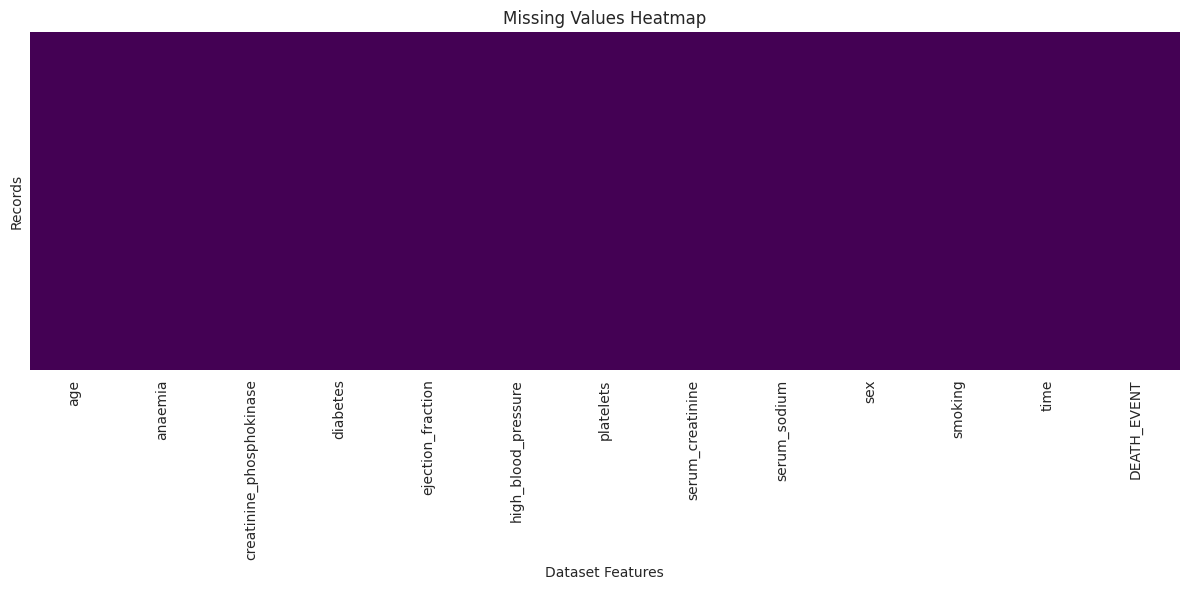

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis",
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Features")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

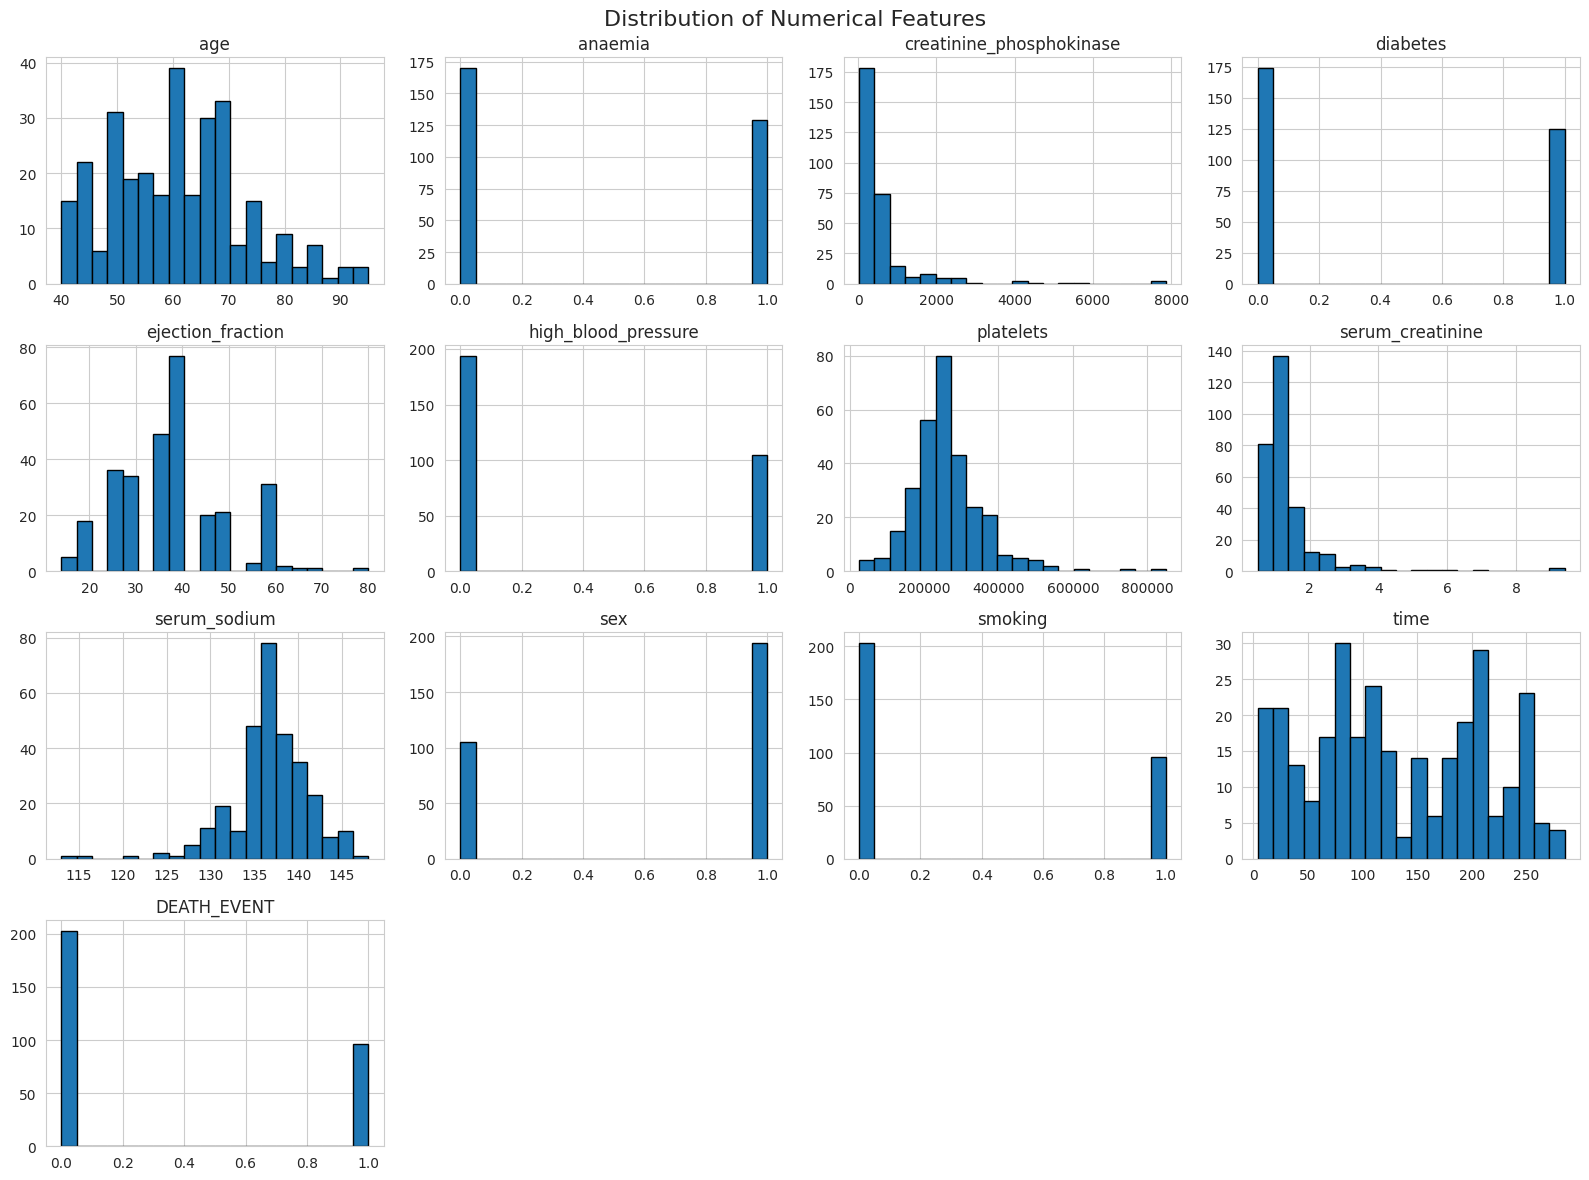

In [ ]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

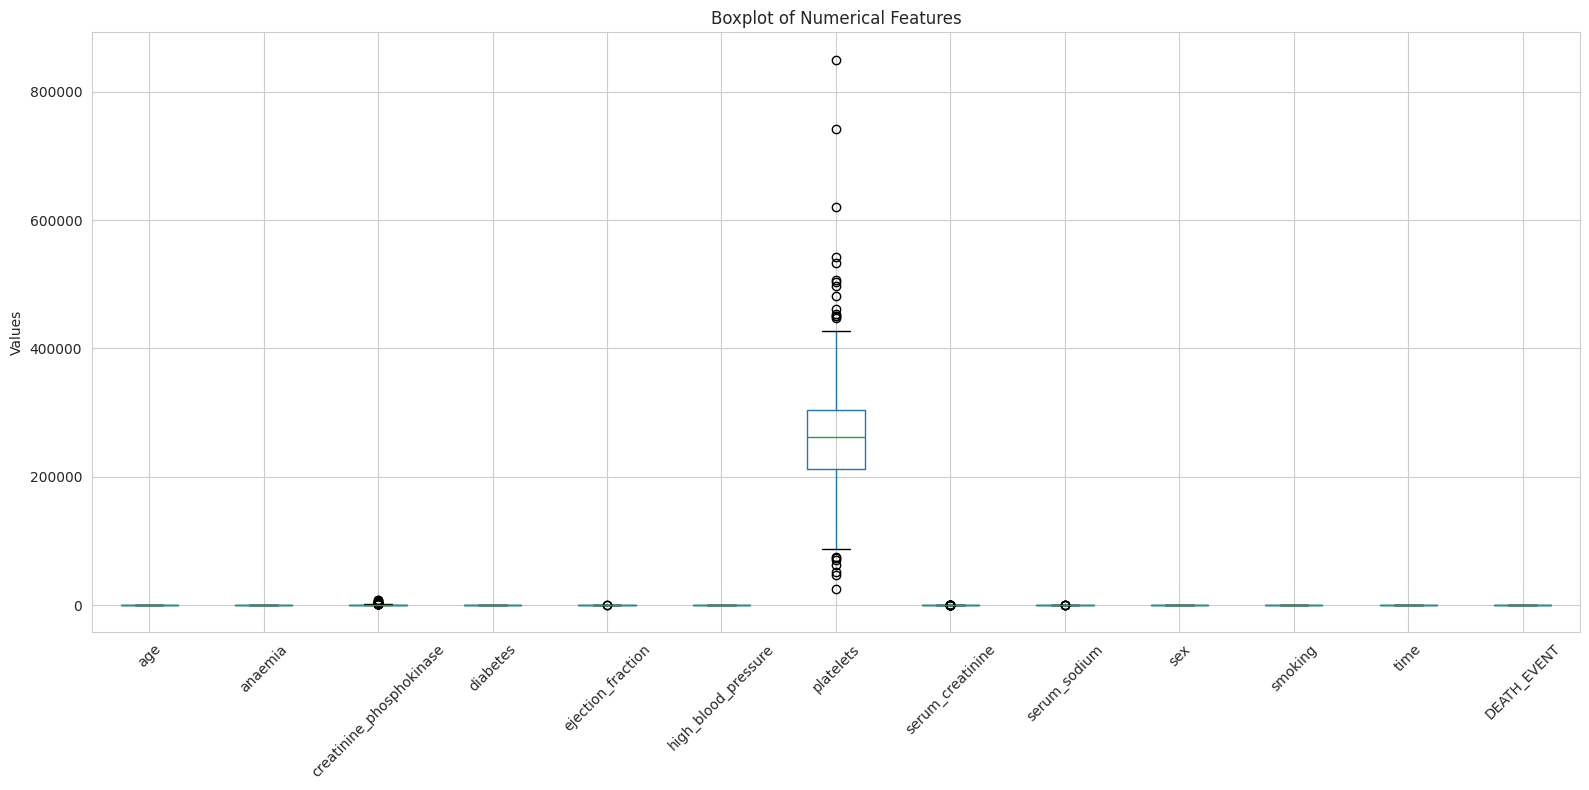

In [ ]:
plt.figure(figsize=(16, 8))

df[numerical_columns].boxplot()

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.ylabel("Values")
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.copy()

numerical_features = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

for column in numerical_features:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print("Missing values after numerical imputation:")
print(df_clean.isnull().sum().sum())

Missing values after numerical imputation:
0


In [ ]:
print("Checking invalid values...")

print("Negative ages:", (df_clean["age"] < 0).sum())
print(
    "Invalid ejection fraction:",
    ((df_clean["ejection_fraction"] < 0) |
     (df_clean["ejection_fraction"] > 100)).sum()
)

df_clean = df_clean[df_clean["age"] >= 0]

df_clean.loc[
    (df_clean["ejection_fraction"] < 0) |
    (df_clean["ejection_fraction"] > 100),
    "ejection_fraction"
] = np.nan

df_clean["ejection_fraction"] = df_clean[
    "ejection_fraction"
].fillna(df_clean["ejection_fraction"].median())

print("\nInconsistency correction completed.")
print("Updated dataset shape:", df_clean.shape)

Checking invalid values...
Negative ages: 0
Invalid ejection fraction: 0

Inconsistency correction completed.
Updated dataset shape: (299, 13)


In [ ]:
outlier_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "time"
]

initial_rows = len(df_clean)

outlier_mask = pd.Series(
    True,
    index=df_clean.index
)

for column in outlier_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask &= (
        (df_clean[column] >= lower_bound) &
        (df_clean[column] <= upper_bound)
    )

df_clean = df_clean[outlier_mask].copy()

removed_rows = initial_rows - len(df_clean)

print("Original records:", initial_rows)
print("Outlier records removed:", removed_rows)
print("Remaining records:", len(df_clean))

Original records: 299
Outlier records removed: 75
Remaining records: 224


In [ ]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 40, 60, np.inf],
    labels=["Below 40", "40-60", "Above 60"],
    right=False
)

print("Age group distribution:")

display(
    df_clean["age_group"].value_counts().sort_index()
)

display(df_clean[["age", "age_group"]].head(10))

Age group distribution:


,count
age_group,
Below 40,0
40-60,99
Above 60,125


,age,age_group
0,75.0,Above 60
2,65.0,Above 60
3,50.0,40-60
5,90.0,Above 60
6,75.0,Above 60
8,65.0,Above 60
11,62.0,Above 60
12,45.0,40-60
13,50.0,40-60
14,49.0,40-60


In [ ]:
df_clean["risk_product"] = (
    df_clean["ejection_fraction"] *
    df_clean["serum_creatinine"]
)

risk_scaler = MinMaxScaler()

df_clean["risk_score"] = risk_scaler.fit_transform(
    df_clean[["risk_product"]]
)

print("Risk score created successfully.")

display(
    df_clean[
        [
            "ejection_fraction",
            "serum_creatinine",
            "risk_product",
            "risk_score"
        ]
    ].head()
)

Risk score created successfully.


,ejection_fraction,serum_creatinine,risk_product,risk_score
0,20.0,1.9,38.0,0.310545
2,20.0,1.3,26.0,0.171495
3,20.0,1.9,38.0,0.310545
5,40.0,2.1,84.0,0.843569
6,15.0,1.2,18.0,0.078795


In [ ]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=["age_group", "sex", "smoking"],
    drop_first=True,
    dtype=int
)

print("Categorical encoding completed.")

print("\nUpdated columns:")
print(df_encoded.columns.tolist())

display(df_encoded.head())

Categorical encoding completed.

Updated columns:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'time', 'DEATH_EVENT', 'risk_product', 'risk_score', 'age_group_40-60', 'age_group_Above 60', 'sex_1', 'smoking_1']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_product,risk_score,age_group_40-60,age_group_Above 60,sex_1,smoking_1
0,75.0,0,582,0,20.0,1,265000.0,1.9,130,4,1,38.0,0.310545,0,1,1,0
2,65.0,0,146,0,20.0,0,162000.0,1.3,129,7,1,26.0,0.171495,0,1,1,1
3,50.0,1,111,0,20.0,0,210000.0,1.9,137,7,1,38.0,0.310545,1,0,1,0
5,90.0,1,47,0,40.0,1,204000.0,2.1,132,8,1,84.0,0.843569,0,1,1,1
6,75.0,1,246,0,15.0,0,127000.0,1.2,137,10,1,18.0,0.078795,0,1,1,0


In [ ]:
X = df_encoded.drop(
    columns=["DEATH_EVENT", "risk_product"]
)

y = df_encoded["DEATH_EVENT"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (224, 15)
Target shape: (224,)

Target distribution:
DEATH_EVENT
0    163
1     61
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nNormalization completed.")

Training data shape: (179, 15)
Testing data shape: (45, 15)

Normalization completed.


In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
y_pred = model.predict(X_test_scaled)

y_probability = model.predict_proba(
    X_test_scaled
)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Death Event", "Death Event"]
    )
)

Model Evaluation Results
------------------------
Accuracy: 0.7778
ROC-AUC Score: 0.9268

Classification Report:
                precision    recall  f1-score   support

No Death Event       0.79      0.94      0.86        33
   Death Event       0.67      0.33      0.44        12

      accuracy                           0.78        45
     macro avg       0.73      0.64      0.65        45
  weighted avg       0.76      0.78      0.75        45



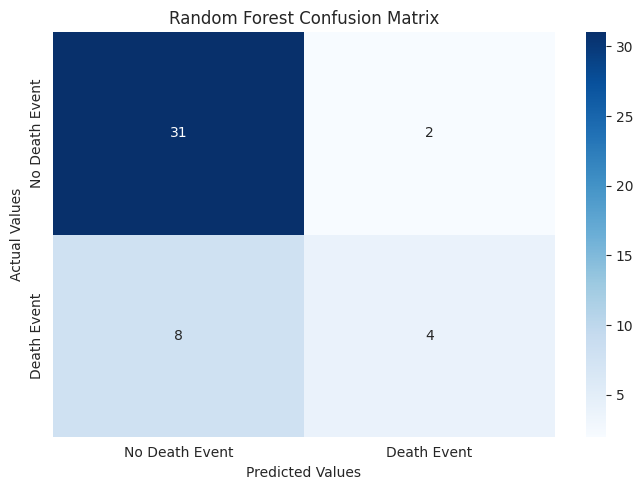

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Death Event", "Death Event"],
    yticklabels=["No Death Event", "Death Event"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()

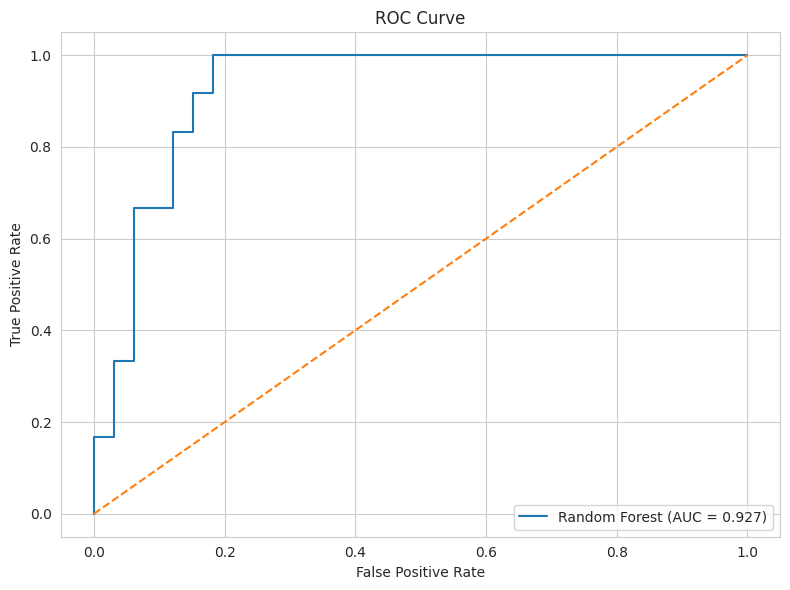

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(
    X_test_scaled
)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


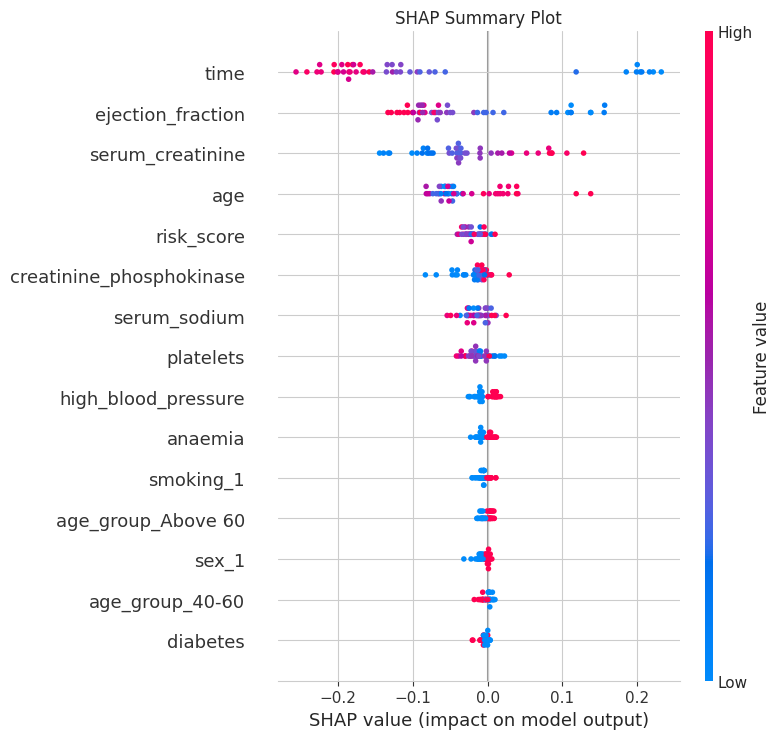

In [ ]:
if isinstance(shap_values, list):
    positive_class_shap = shap_values[1]
elif shap_values.ndim == 3:
    positive_class_shap = shap_values[:, :, 1]
else:
    positive_class_shap = shap_values

plt.figure()

shap.summary_plot(
    positive_class_shap,
    X_test_scaled,
    show=False
)

plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()

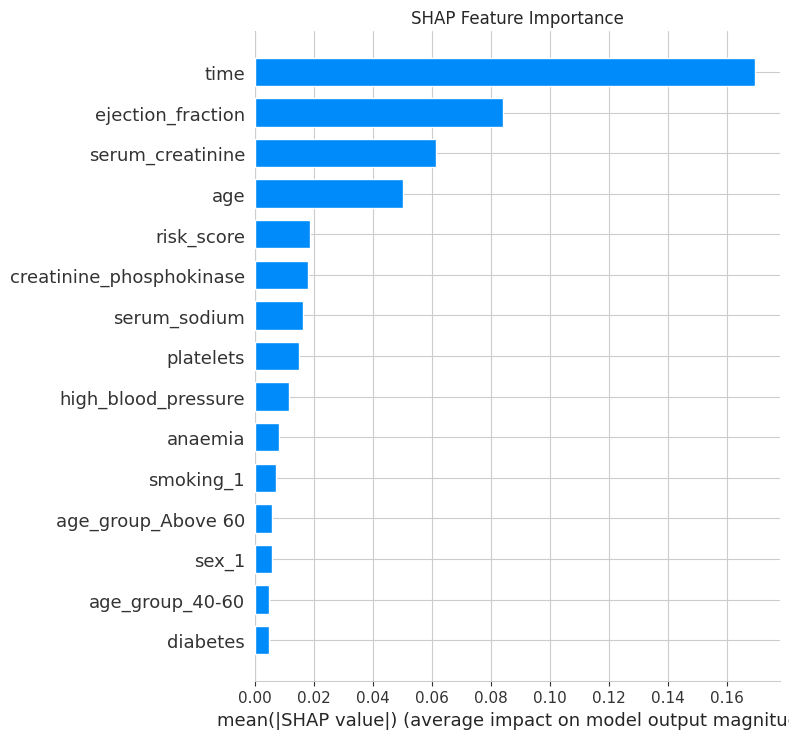

In [ ]:
shap.summary_plot(
    positive_class_shap,
    X_test_scaled,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
sample_index = 0

sample = X_test_scaled.iloc[[sample_index]]

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print("Predicted class:", prediction)
print("Predicted probability of death event:", round(probability, 4))

if prediction == 1:
    print("Model prediction: Death Event")
else:
    print("Model prediction: No Death Event")

if hasattr(shap_values, "base_values"):
    print("SHAP explanation available.")

Predicted class: 0
Predicted probability of death event: 0.125
Model prediction: No Death Event


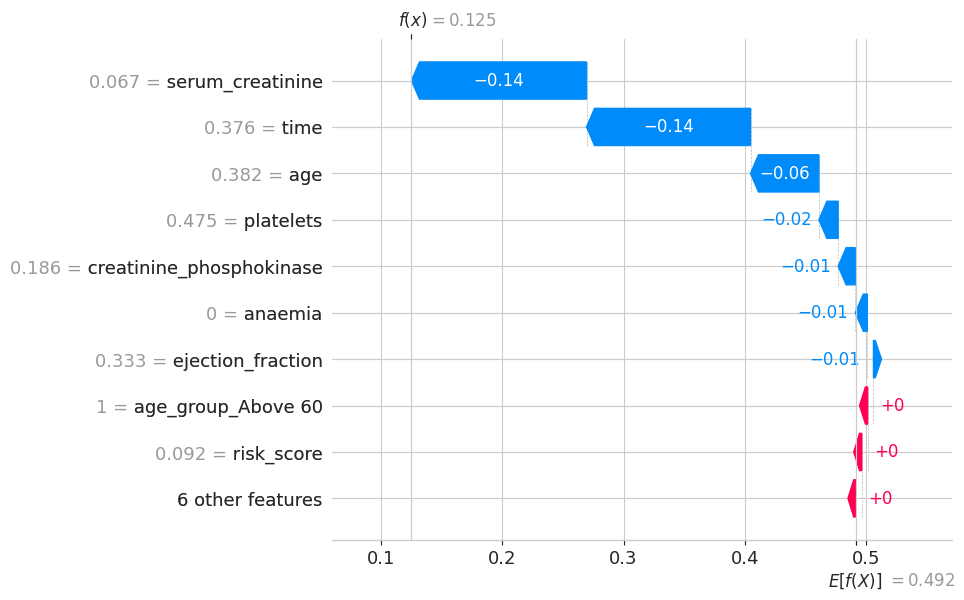

In [ ]:
shap_explanation = explainer(
    X_test_scaled
)

shap.plots.waterfall(
    shap_explanation[sample_index, :, 1]
)

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_scaled.values,
    feature_names=X_train_scaled.columns.tolist(),
    class_names=["No Death Event", "Death Event"],
    mode="classification",
    discretize_continuous=True
)

print("LIME explainer initialized successfully.")

LIME explainer initialized successfully.


In [ ]:
lime_exp = lime_explainer.explain_instance(
    X_test_scaled.iloc[0].values,
    model.predict_proba,
    num_features=10
)

lime_exp.show_in_notebook(show_table=True)

print("\nLIME explanation:")
for feature, contribution in lime_exp.as_list():
    print(feature, ":", round(contribution, 4))


LIME explanation:
ejection_fraction <= 0.33 : 0.165
serum_creatinine <= 0.20 : -0.0873
0.26 < time <= 0.42 : -0.0653
risk_score <= 0.21 : 0.0199
0.00 < high_blood_pressure <= 1.00 : 0.0182
0.48 < serum_sodium <= 0.60 : 0.0146
0.00 < smoking_1 <= 1.00 : 0.0135
anaemia <= 0.00 : -0.0124
0.00 < sex_1 <= 1.00 : 0.0104
0.16 < creatinine_phosphokinase <= 0.47 : 0.0101


In [ ]:
print("FINAL LAB ASSIGNMENT 11 SUMMARY")
print("=" * 45)

print("Original dataset shape:", df.shape)
print("Processed dataset shape:", df_encoded.shape)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Model: Random Forest Classifier")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nExplainable AI methods:")
print("1. SHAP")
print("2. LIME")

df_encoded.to_csv(
    "/content/processed_heart_failure_dataset.csv",
    index=False
)

print("\nProcessed dataset saved successfully.")

FINAL LAB ASSIGNMENT 11 SUMMARY
Original dataset shape: (299, 13)
Processed dataset shape: (224, 17)
Training records: 179
Testing records: 45
Model: Random Forest Classifier
Accuracy: 0.7778
ROC-AUC: 0.9268

Explainable AI methods:
1. SHAP
2. LIME

Processed dataset saved successfully.
